# Minimum weight perfect matching implementation

**Reference paper**: https://arxiv.org/pdf/2105.13082

### First implementation: k=1 repetition code

Num qubits `n=3`; check matrix `H=[[1, 1, 0]; [0, 1, 1]]` rank 2; `n - rank(H) = 1` data qubit

We use `stim` repetition code simulator with a `Matching` object we define from our known check matrix 

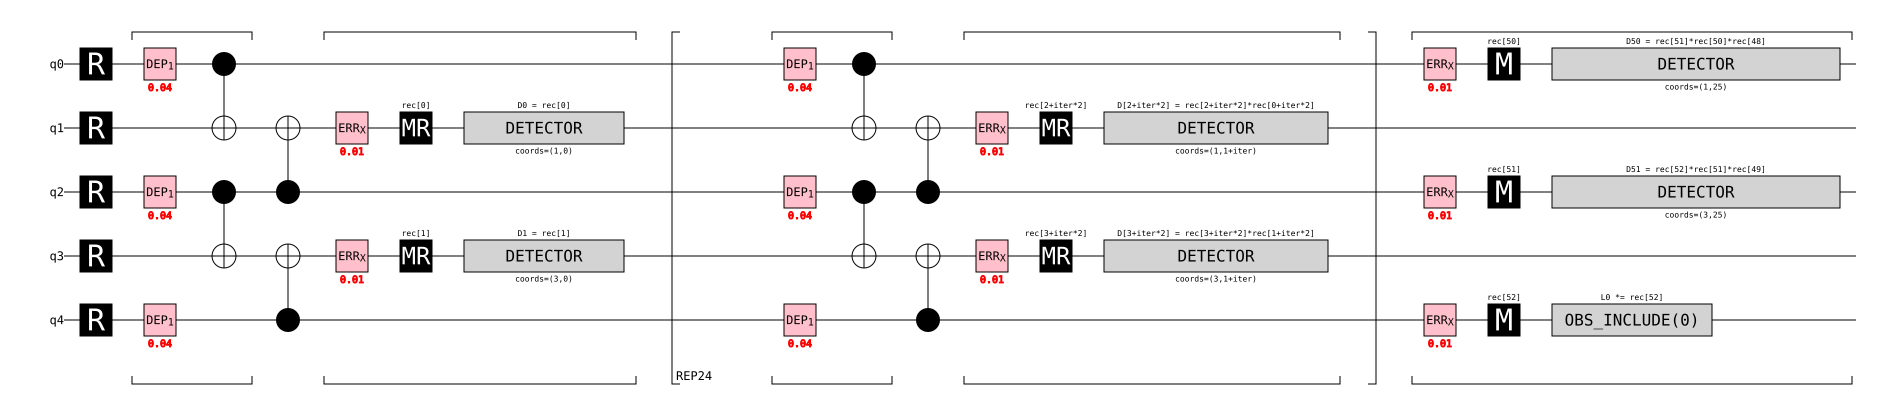

In [41]:
# construct stim simulator for data generation. repetition code circuit d=3
import stim
repetition_ckt = stim.Circuit.generated(
    "repetition_code:memory",
    rounds=25,
    distance=3,
    before_measure_flip_probability=0.01,
    before_round_data_depolarization=0.04
)
repetition_ckt.diagram('timeline-svg')

In [42]:
# show errors as 1 when simulating the circuit. tracks each channel
sampler = repetition_ckt.compile_sampler()
result = sampler.sample(shots=3)[0]
print("".join("1" if e else "_" for e in result))

_______________________________11111111111111111111_1


In [43]:
# now show errors tracking the detector
# results are much more sparse because we are tracking detected errors, not just whether error happens or not on channel
# foundation for error correction: flips come in pairs
detector_sampler = repetition_ckt.compile_detector_sampler()
result = detector_sampler.sample(shots=3)[0]
print("".join("1" if e else "_" for e in result))

____________________________________1_1_____________


## Matching decoder initialization

Now we initialize a detector error model (DEM) directly from the circuit data, and use it to construct a `pymatching.Matching` graph that encodes the syndrome data from the circuit as a MWPM graph

In [51]:
from pymatching import Matching

def mwpm_from_dem(meas_err_rate: float, data_err_rate: float, suppress_results: bool=False, distance: int=3, rounds: int=25):
    repetition_ckt = stim.Circuit.generated(
        "repetition_code:memory",
        rounds=rounds,
        distance=distance,
        before_measure_flip_probability=meas_err_rate,
        before_round_data_depolarization=data_err_rate,
    )
    dem = repetition_ckt.detector_error_model(decompose_errors=True)
    detector_sampler = repetition_ckt.compile_detector_sampler()
    # dynamically adjust detector shots based on error rate
    if meas_err_rate >= 1e-2:
        detector_shots = 10**3
    elif meas_err_rate < 1e-2 and meas_err_rate >= 1e-3:
        detector_shots = 10**4
    else:
        detector_shots = 10**5

    detection_events, observable_flips = detector_sampler.sample(shots=detector_shots, separate_observables=True)

    m = Matching.from_detector_error_model(dem)
    predictions = m.decode_batch(detection_events)

    prediction_errors = 0
    for i, flip in enumerate(observable_flips):
        if predictions[i] != flip:
            prediction_errors += 1

    prediction_error_rate = round(prediction_errors / len(predictions), 3)
    if not suppress_results:
        print(f"MWPM error rate: {prediction_error_rate}")
        print(f"Missed {prediction_errors} / {len(predictions)} detector errors.")

    return prediction_error_rate

error_rate = mwpm_from_dem(0.04, 0.01)

MWPM error rate: 0.021
Missed 21 / 1000 detector errors.


MWPM does pretty good with low error rate. Now let's vary error rate and see results

Text(0, 0.5, 'Average errors (actual pauli flips vs. predicted)')

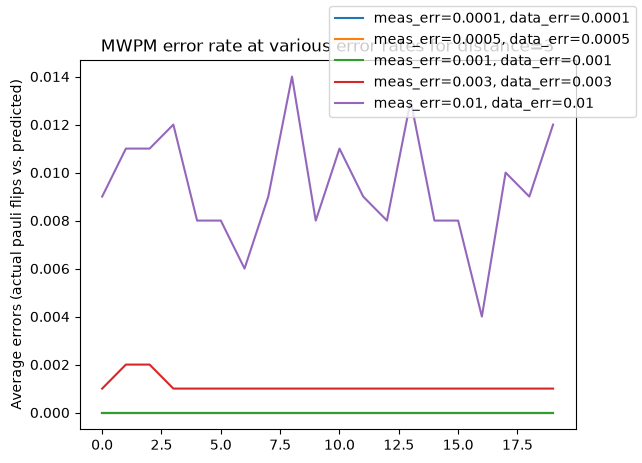

In [ ]:
import matplotlib.pyplot as plt

def run_mwpm(meas_err_rate: float, data_err_rate: float, num_shots: int = 20, distance: int = 3):
    results = []
    for i in range(num_shots):
        prediction_error_rate = mwpm_from_dem(meas_err_rate, data_err_rate, distance=distance, suppress_results=True)
        results.append(prediction_error_rate)
    return results

# hardware-realistic error rates
error_rates = [
    (1e-4, 1e-4), 
    (5e-4, 5e-4), 
    (1e-3, 1e-3),
    (3e-3, 3e-3),
    (1e-2, 1e-2)
]
num_shots = 20
distance = 3
result = []
for pair in error_rates:
    meas_err, data_err = pair
    d_3_error_rate = run_mwpm(meas_err_rate=meas_err, data_err_rate=data_err, distance=distance, num_shots=num_shots)
    result.append((d_3_error_rate, meas_err, data_err))

fig, ax = plt.subplots()
for i, res in enumerate(result):
    meas_err = result[i][1]
    data_err = result[i][2]
    ax.plot(res[0], label=f"meas_err={meas_err}, data_err={data_err}")
fig.legend(loc='outside right upper')
plt.title(f"MWPM error rate at various error rates for distance={distance}")
plt.ylabel("Average errors (actual pauli flips vs. predicted)")

Notes:
- MWPM can't predict measure error so it performs worst with high measure error
- performs about the same for 0.25 and 0.5 data error rate. 
    - class of error in stim simulator is just X or Z flips which in simple repetition code are more often single-edges, able to be predicted by MWPM effectively. even double-faults which would normally produce double edge get weeded out if there wasn't a third fault on the third data qubit, the edge shows up singular on other ancilla 

### Now try couple rounds on greater distance

Text(0, 0.5, 'Average errors (actual pauli flips vs. predicted)')

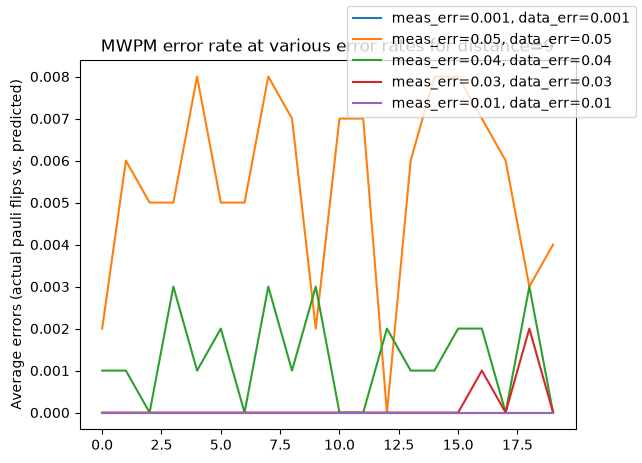

In [ ]:
import numpy as np
# scale error rates up since distance is greater
error_rates = [
    (1e-3, 1e-3), 
    (5e-2, 5e-2), 
    (4e-2, 4e-2),
    (3e-2, 3e-2),
    (1e-2, 1e-2)
]
num_shots = 20
distance = 9
result = []
for pair in error_rates:
    meas_err, data_err = pair
    d_9_error_rate = run_mwpm(meas_err_rate=meas_err, data_err_rate=data_err, distance=distance, num_shots=num_shots)
    result.append((d_9_error_rate, meas_err, data_err))

fig, ax = plt.subplots()
for i, res in enumerate(result):
    meas_err = result[i][1]
    data_err = result[i][2]
    ax.plot(res[0], label=f"meas_err={meas_err}, data_err={data_err}")
fig.legend(loc='outside right upper')
plt.title(f"MWPM error rate at various error rates for distance={distance}")
plt.ylabel("Average errors (actual pauli flips vs. predicted)")
    

## Discussion of results so far

The near-perfect accuracy of MWPM on repetition code as demonstrated is an artifact of the type of errors that can possibly manifest on repetition code. Repetition code only protects against one Pauli type of error, depending on the parity-check ran from data to ancilla qubit. Here we track X-flips and MWPM is able to pick up on almost all of them because the DEM in repetition code is graphlike (TODO: need to prove this mathematically to improve quality of discussion), and MWPM is a graph algorithm. 

Practical limitations: 
- Real hardware has 3 types of Pauli flips (X, Z, Y) that repetition code can only see one of
- Since the repetition code DEM is graphlike, it cannot represent hyperedges (>2 correlated nodes for given error pattern); hyperedges are more common in surface code topologies so MWPM breaks down (TODO: run MWPM against surface code and demonstrate worse accuracy)